# Real-to-Sim Sensor Model, Part 5: The Simulator
| Part | Notebook | What it does |
|---|---|---|
| 1–3 | `12_1` – `12_3` | Camera + CAD render, labels, dataset |
| 4 | `12_4`, `12_4b` | Model: 10 inputs → p, μ, σ per pixel |
| **5** | **`12_5_real2sim_simulator`** | **Any camera pose → simulated noisy scan** |
| 6 | | Export for the 4_2 / 6 pipeline |

**How a simulated scan is made** (`real2sim_sim.Simulator`):
```
camera pose → render CAD → 10 inputs → model → p, μ, σ per pixel
                                                   │
         Cloud A (blurred noise) ── drop the pixel if dice < p        → dropouts in patches
         Cloud B (blurred noise) ── depth = CAD + μ + σ × noise,      → errors in smooth blobs
                                    rounded to whole mm (like the sensor)
                                                   │
                                     unproject kept pixels → 3D points
```
The model says **how likely** a dropout is and **how big** the error is at each pixel; the two clouds are the dice (random numbers, mostly between −1 and +1). They are **blurred** because the real sensor's errors are not independent from pixel to pixel: neighbouring pixels drop together and read too far or too close together (the blobs in the 12_3 maps).

**What this notebook checks**
1. The size of the real blobs and patches, measured on validation views, and the recipe for the two clouds that reproduces it.
2. One unseen view (TH1041AV): real scan vs simulated scan, side by side.
3. All 288 unseen views: do the simulated scans have the same statistics as the real ones?
4. A cut through the pocket: real points vs simulated points vs CAD.

In [1]:
# ==========================================
# CONFIGURATION
# ==========================================
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d
from matplotlib.colors import ListedColormap
from scipy.special import ndtr

import real2sim as rs
import real2sim_model as rm
import real2sim_sim as sim
from seed_utils import SEED

EXPERIMENT = "test_11_real_pocket"
ALL_WORKPIECES = ["TH1021AV", "TH1031AV", "TH1041AV", "TH1051AV"]
TEST_WP, VAL_FRACTION = "TH1041AV", 0.3          # same split as Part 4
MODEL_PATH = f"simulation/real2sim/{EXPERIMENT}/model_10in_test-{TEST_WP}.pt"
CAL_VIEWS = 30            # validation views used to measure the blob / patch size
EXAMPLE_VIEWS = [100, 287]
CUT_VIEW = 100            # view for the cut through the pocket (section 4)
MM_PER_PX = 0.74          # 960x540 grid at ~500 mm

cam = rs.Camera.native().downscaled(2)
OUT_DIR = f"simulation/real2sim/{EXPERIMENT}"
model, INPUTS, meta = rm.load_model(MODEL_PATH, "cpu")
print(f"model {MODEL_PATH}: {len(INPUTS)} inputs {INPUTS}\n  {meta}")

df = rs.load_dataset(EXPERIMENT, ALL_WORKPIECES, cam)
split = rm.split_views(df, TEST_WP, VAL_FRACTION, seed=SEED)
val, test = df[split["val"]], df[split["test"]]


def view_rows(frame, wp, v):
    return frame[(frame.workpiece == wp) & (frame.view == v)]


def to_map(rows, values):
    img = np.full((cam.height, cam.width), np.nan)
    img[rows.v.to_numpy(), rows.u.to_numpy()] = values
    return img

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
model simulation/real2sim/test_11_real_pocket/model_10in_test-TH1041AV.pt: 10 inputs ['xn', 'yn', 'z', 'nx', 'ny', 'nz', 'theta_inc', 'edge_mm', 'deeper_mm', 'closer_mm']
  {'test_workpiece': 'TH1041AV', 'val_fraction': 0.3, 'best_epoch': 15, 'seed': 42}


## 1. How big are the real blobs and patches?
On validation views (never the test workpiece), take what the model **cannot** predict:
- **depth**: (`e_z` − μ) / σ on kept pixels, the "surprise" in units of σ
- **drops**: `y_drop` − p on all CAD pixels

and measure how similar a pixel's surprise is to that of a pixel *d* away (correlation: 1 = always the same, 0 = unrelated). Independent dice would give 0 for every *d* > 0. The real curves stay high for several millimetres: that is the blob / patch size.

Each cloud is built from two ingredients: **patches** (noise blurred by `blur_px`) plus a share `fine_share` of a **finer grain** (noise blurred by `fine_px`). The recipe is found by trying many combinations and keeping the one whose curve is closest to the real curve:
- Cloud B (depth): the simulated depth is rounded to whole mm before its curve is measured, exactly like the real sensor's depth.
- Cloud A (drops): drops are simulated with each recipe on the same views (a drop is a yes/no decision).

Also measured here: whether σ has the right width on the validation views. If fewer than 68% of the real errors fall within ±1σ, σ is widened by the factor that makes it 68% (`sigma_scale`).

validation: 65.9% of errors within 1 sigma (ideal 68.3) -> sigma_scale = 1.050
Cloud B (depth): patches 5.50 px (~4.1 mm) + 18% finer grain of 1.25 px
Cloud A (drops): patches 5.00 px (~3.7 mm) + 0% finer grain of 0.00 px
(30 validation views, 119 s)


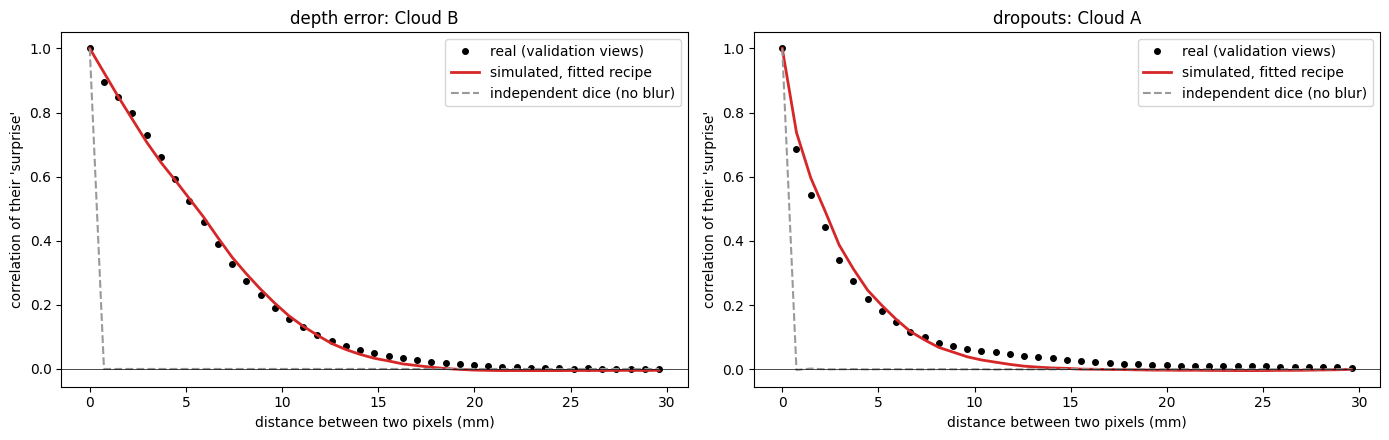

saved simulation/real2sim/test_11_real_pocket\simulator_test-TH1041AV.json (Part 6 rebuilds the same simulator from it: sim.Simulator.from_config)


In [2]:
# ==========================================
# 1. MEASURE THE REAL BLOB / PATCH SIZE AND FIT THE TWO CLOUDS
# ==========================================
t0 = time.time()
keys = list(val.groupby(["workpiece", "view"], observed=True).size().index)
rng = np.random.default_rng(SEED)
keys = [keys[i] for i in sorted(rng.choice(len(keys), CAL_VIEWS, replace=False))]
cal = []      # per view, cropped around the part (same pixel pairs, much faster): masks, p, residuals, z, mu, sigma
for wp, v in keys:
    rows = view_rows(val, wp, v)
    p, mu, sd = rm.predict(model, rows[INPUTS].to_numpy(np.float32))
    e = rows.e_z.to_numpy()
    full = dict(mask=~np.isnan(to_map(rows, np.ones(len(rows)))), kept=~np.isnan(to_map(rows, e)),
                p=to_map(rows, p), r=to_map(rows, (e - mu) / sd), d=to_map(rows, rows.y_drop.to_numpy() - p),
                z=to_map(rows, rows.z.to_numpy()), mu=to_map(rows, mu), sd=to_map(rows, sd))
    v0, v1, u0, u1 = rs.mask_bbox(full["mask"], margin=40)
    cal.append({k: m[v0:v1, u0:u1] for k, m in full.items()})

# sigma width on ALL validation pixels
p_all, mu_all, sd_all = rm.predict(model, val[INPUTS].to_numpy(np.float32))
k_all = val.e_z.notna().to_numpy()
abs_r = np.abs(val.e_z.to_numpy()[k_all] - mu_all[k_all]) / sd_all[k_all]
SIGMA_SCALE = max(1.0, float(np.quantile(abs_r, 0.6827)))
print(f"validation: {np.mean(abs_r < 1) * 100:.1f}% of errors within 1 sigma (ideal 68.3) -> sigma_scale = {SIGMA_SCALE:.3f}")
for c in cal:
    c["sd"] = c["sd"] * SIGMA_SCALE

d, real_depth = sim.field_correlation([np.nan_to_num(c["r"]) for c in cal], [c["kept"] for c in cal])
_, real_drop = sim.field_correlation([np.nan_to_num(c["d"]) for c in cal], [c["mask"] for c in cal])
fit_d = (d >= 1) & (d <= 30)     # the curves are compared at 1..30 px

# the same random numbers for every recipe, so that recipes are compared fairly
g = np.random.default_rng(SEED)
for c in cal:
    c["w1"], c["w2"] = g.standard_normal(c["mask"].shape), g.standard_normal(c["mask"].shape)
_blurred = {}


def recipe_field(i, recipe):
    c = cal[i]
    for key in [("w1", recipe.blur_px), ("w2", recipe.fine_px)]:
        if (i,) + key not in _blurred:
            _blurred[(i,) + key] = sim.blur_unit(c[key[0]], key[1])
    patches = _blurred[(i, "w1", recipe.blur_px)]
    return patches if recipe.fine_share <= 0 else sim.mix(patches, _blurred[(i, "w2", recipe.fine_px)], recipe.fine_share)


def depth_curve(recipe):
    # simulated depth, rounded to whole mm like the sensor, turned into the same 'surprise' as the real one
    maps = []
    for i, c in enumerate(cal):
        e = np.round(c["z"] + c["mu"] + c["sd"] * recipe_field(i, recipe)) - c["z"]
        maps.append(np.nan_to_num((e - c["mu"]) / c["sd"]))
    return sim.field_correlation(maps, [c["kept"] for c in cal])[1]


def drop_curve(recipe):
    maps = [np.where(c["mask"], (ndtr(recipe_field(i, recipe)) < np.nan_to_num(c["p"])) - np.nan_to_num(c["p"]), 0)
            for i, c in enumerate(cal)]
    return sim.field_correlation(maps, [c["mask"] for c in cal])[1]


def best_recipe(curve, real, blurs, shares, fines):
    trials = []
    for b in blurs:
        for s in shares:
            for f in (fines if s > 0 else [0.0]):
                rec = sim.NoiseRecipe(round(float(b), 3), round(float(s), 3), round(float(f), 3))
                trials.append((np.sum((curve(rec)[fit_d] - real[fit_d]) ** 2), rec))
    return min(trials, key=lambda t: t[0])[1]


# Cloud B (depth): coarse search, then a finer search around the best
rec = best_recipe(depth_curve, real_depth, np.arange(4.5, 7.01, 0.5), np.arange(0, 0.51, 0.05), [0.0, 0.5, 1.0, 1.5, 2.0, 2.5])
DEPTH_NOISE = best_recipe(depth_curve, real_depth, rec.blur_px + np.array([-0.25, 0, 0.25]),
                          np.clip(rec.fine_share + np.array([-0.025, 0, 0.025]), 0, 1),
                          [max(rec.fine_px + x, 0.0) for x in (-0.25, 0, 0.25)])
# Cloud A (drops)
DROP_NOISE = best_recipe(drop_curve, real_drop, [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0], [0.0, 0.2, 0.4, 0.6], [0.0])
for name, r in [("Cloud B (depth)", DEPTH_NOISE), ("Cloud A (drops)", DROP_NOISE)]:
    print(f"{name}: patches {r.blur_px:.2f} px (~{r.blur_px * MM_PER_PX:.1f} mm) + {r.fine_share:.0%} finer grain "
          f"of {r.fine_px:.2f} px")
print(f"({CAL_VIEWS} validation views, {time.time() - t0:.0f} s)")

# check: simulated curves with the fitted recipes
sim_depth = depth_curve(DEPTH_NOISE)
sim_drop = drop_curve(DROP_NOISE)
ind_drop = drop_curve(sim.NoiseRecipe(0.0))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, real, simulated, title in [(axes[0], real_depth, sim_depth, "depth error: Cloud B"),
                                   (axes[1], real_drop, sim_drop, "dropouts: Cloud A")]:
    ax.plot(d * MM_PER_PX, real, "o", color="k", ms=4, label="real (validation views)")
    ax.plot(d * MM_PER_PX, simulated, "-", color="#d62728", lw=2, label="simulated, fitted recipe")
    ax.plot(d * MM_PER_PX, ind_drop if "drop" in title else np.r_[1, np.zeros(len(d) - 1)], "--", color="#999999",
            label="independent dice (no blur)")
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xlabel("distance between two pixels (mm)")
    ax.set_ylabel("correlation of their 'surprise'")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part5_noise_size.png"), dpi=110)
plt.show()

simulator = sim.Simulator(rs.real_dirs(EXPERIMENT, TEST_WP)["cad"], MODEL_PATH, cam, DEPTH_NOISE, DROP_NOISE,
                          sigma_scale=SIGMA_SCALE, round_mm=True)
CONFIG_PATH = os.path.join(OUT_DIR, f"simulator_test-{TEST_WP}.json")
simulator.save_config(CONFIG_PATH, grid=[cam.width, cam.height], calibration_views=CAL_VIEWS, seed=SEED)
print("saved", CONFIG_PATH, "(Part 6 rebuilds the same simulator from it: sim.Simulator.from_config)")
T_test = rs.load_cad_pose(EXPERIMENT, TEST_WP)
raw_test = rs.real_dirs(EXPERIMENT, TEST_WP)["raw"]

## 2. One unseen view: real vs simulated
TH1041AV was never used for training or for the recipes. For each view: the real labels (left of each pair) and one simulated scan (right). The simulated scan is **not** supposed to copy the real one pixel by pixel: the blobs and patches are random, so another draw gives other blobs. It should look like **the same kind of scan**: dropouts along the same edges, patches of similar size, too far / too close in the same places, blobs of similar size and strength.

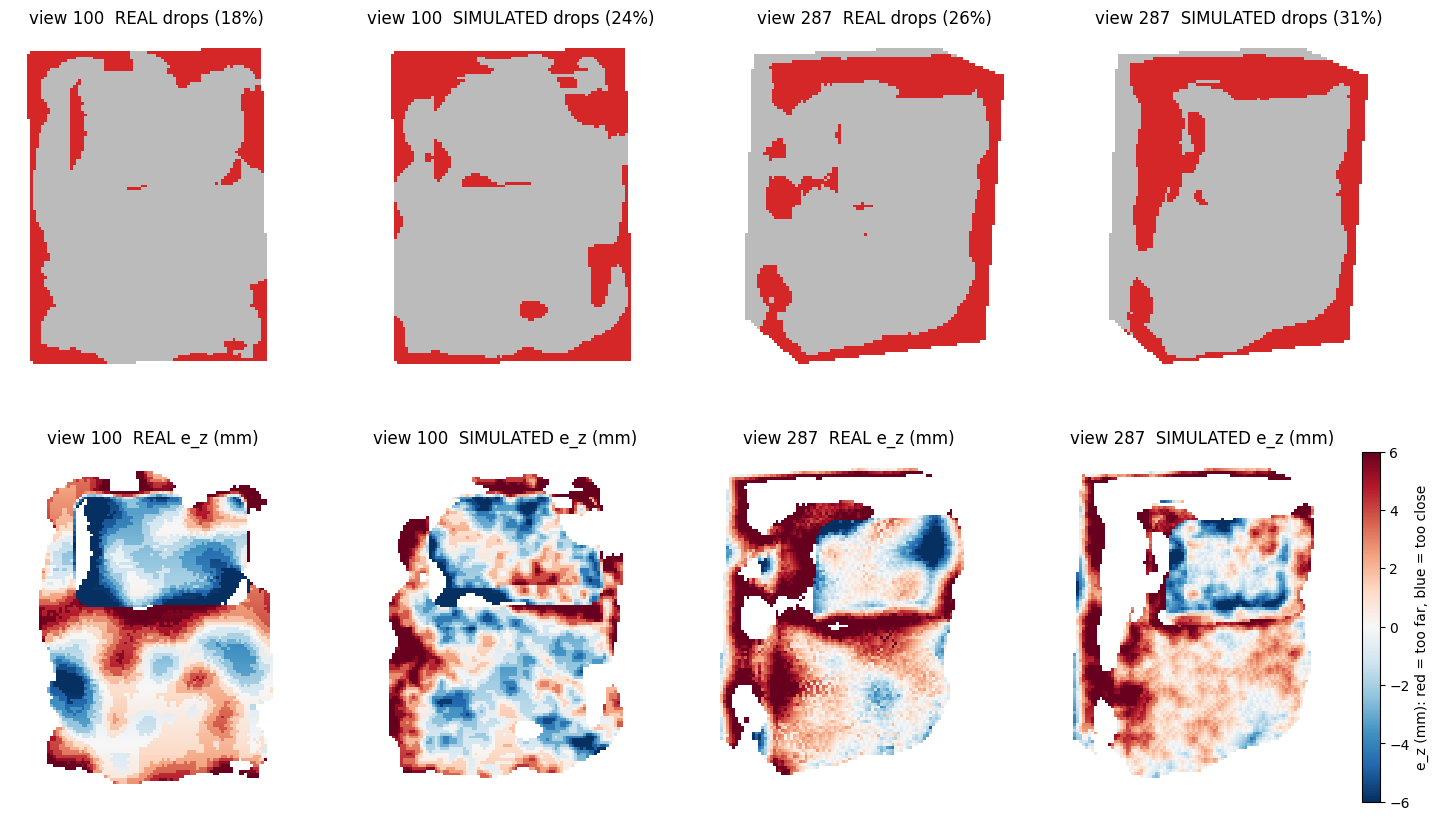

In [3]:
# ==========================================
# 2. REAL vs SIMULATED, ONE VIEW AT A TIME
# ==========================================
drop_cmap = ListedColormap(["#bbbbbb", "#d62728"])
fig, axes = plt.subplots(2, 2 * len(EXAMPLE_VIEWS), figsize=(9 * len(EXAMPLE_VIEWS), 10))
for j, v in enumerate(EXAMPLE_VIEWS):
    rows = view_rows(test, TEST_WP, v)
    out = simulator.simulate(rs.real_camera_pose(raw_test, v, T_test), np.random.default_rng([SEED, v]))
    m = out["maps"]["mask"]
    b0, b1, a0, a1 = rs.mask_bbox(m, margin=6)
    crop = (slice(b0, b1), slice(a0, a1))
    real_drop = to_map(rows, rows.y_drop.to_numpy())
    sim_drop = np.where(m, out["drop"].astype(float), np.nan)
    panels = [(axes[0, 2 * j], real_drop, drop_cmap, 0, 1, f"view {v}  REAL drops ({np.nanmean(real_drop) * 100:.0f}%)"),
              (axes[0, 2 * j + 1], sim_drop, drop_cmap, 0, 1, f"view {v}  SIMULATED drops ({np.nanmean(sim_drop) * 100:.0f}%)"),
              (axes[1, 2 * j], to_map(rows, rows.e_z.to_numpy()), "RdBu_r", -6, 6, f"view {v}  REAL e_z (mm)"),
              (axes[1, 2 * j + 1], out["e_sim"], "RdBu_r", -6, 6, f"view {v}  SIMULATED e_z (mm)")]
    for ax, img, cmap, lo, hi, title in panels:
        im = ax.imshow(img[crop], cmap=cmap, vmin=lo, vmax=hi, interpolation="nearest")
        ax.set_title(title)
        ax.axis("off")
fig.colorbar(im, ax=axes[1, :].tolist(), fraction=0.02, pad=0.01, label="e_z (mm): red = too far, blue = too close")
plt.savefig(os.path.join(OUT_DIR, "part5_real_vs_sim_views.png"), dpi=100, bbox_inches="tight")
plt.show()

## 3. All 288 unseen views: same statistics?
One simulated scan per view of TH1041AV (each with its own fixed seed), compared with the real scans of the same views:
- **top left**: dropout rate of every view, real vs simulated (on the diagonal = right amount of dropout per view)
- **top right**: all depth errors pooled (the shapes should overlap)
- **bottom left**: dropout vs distance to the nearest edge (the strongest pattern of the real sensor)
- **bottom right**: median depth error next to a drop-off and next to a rise (the step pattern from 12_3)

simulated 288 views in 110 s


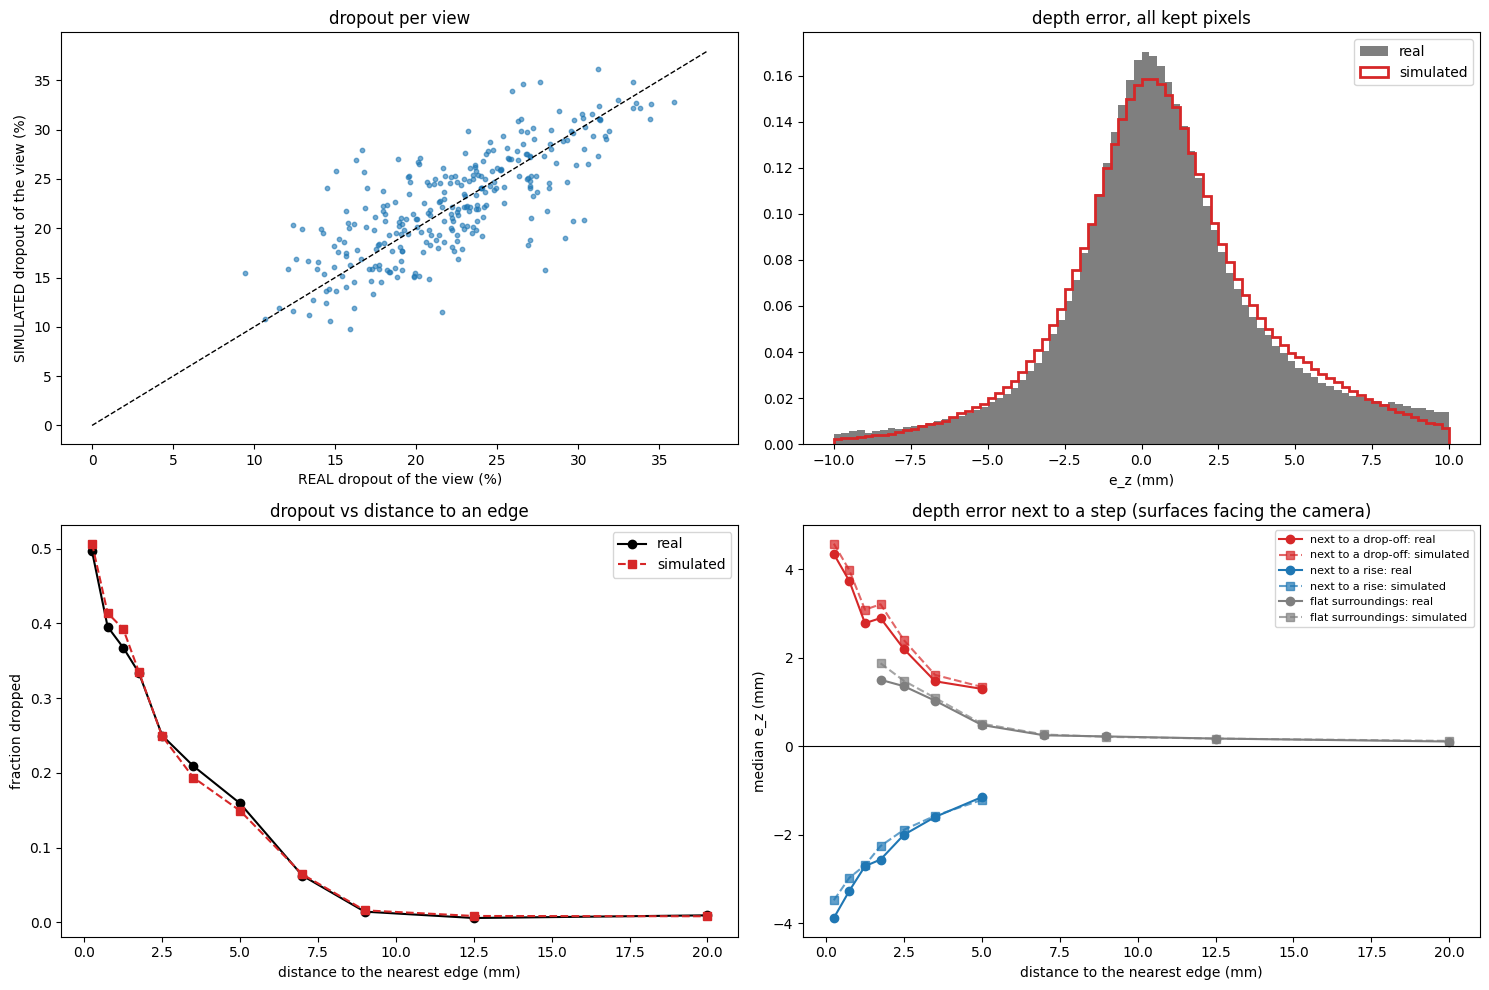

,real,simulated
dropout rate,0.225,0.228
e_z median (mm),0.525,0.585
e_z 10% (mm),-2.966,-3.060
e_z 90% (mm),5.101,5.262
e_z std (mm),3.318,3.438


per-view dropout: correlation real vs simulated 0.77, mean abs difference 2.8 percentage points


In [4]:
# ==========================================
# 3. STATISTICS OVER ALL TEST VIEWS
# ==========================================
t0 = time.time()
# grain check: the recipe used before the fix (per-pixel shake, no rounding), on the same views and dice seeds
previous = sim.Simulator(rs.real_dirs(EXPERIMENT, TEST_WP)["cad"], MODEL_PATH, cam,
                         sim.NoiseRecipe(blur_px=5.23, fine_share=0.14, fine_px=0.0), DROP_NOISE,
                         sigma_scale=SIGMA_SCALE, round_mm=False)
REGIONS = [("flat (> 5 mm from an edge)", 5, np.inf), ("2-5 mm from an edge", 2, 5), ("right at an edge (< 2 mm)", 0, 2)]
grain = {(reg, src): np.zeros(3) for reg, _, _ in REGIONS for src in ("real", "simulated", "previous recipe")}
per_view, pix = [], []
for v in sorted(test.view.unique()):
    rows = view_rows(test, TEST_WP, v)
    T_cam = rs.real_camera_pose(raw_test, v, T_test)
    maps = simulator.predict_maps(T_cam)
    out = simulator.simulate(T_cam, np.random.default_rng([SEED, v]), maps=maps)
    out_prev = previous.simulate(T_cam, np.random.default_rng([SEED, v]), maps=maps)
    edge = maps["edge_mm"]
    for src, E in [("real", to_map(rows, rows.e_z.to_numpy())), ("simulated", out["e_sim"]), ("previous recipe", out_prev["e_sim"])]:
        for a, b in [((slice(None), slice(0, -1)), (slice(None), slice(1, None))),     # left-right neighbours
                     ((slice(0, -1), slice(None)), (slice(1, None), slice(None)))]:    # up-down neighbours
            diff = E[a] - E[b]
            near = np.minimum(edge[a], edge[b])
            for reg, lo, hi in REGIONS:
                x = diff[~np.isnan(diff) & (near >= lo) & (near < hi)]
                grain[(reg, src)] += [len(x), x.sum(), (x ** 2).sum()]
    vv, uu = rows.v.to_numpy(), rows.u.to_numpy()
    s_drop, s_e = out["drop"][vv, uu], out["e_sim"][vv, uu]
    per_view.append(dict(view=v, real=rows.y_drop.mean(), sim=s_drop.mean()))
    pix.append(pd.DataFrame(dict(edge_mm=rows.edge_mm.to_numpy(), deeper=rows.deeper_mm.to_numpy(),
                                 closer=rows.closer_mm.to_numpy(), theta=rows.theta_inc.to_numpy(),
                                 real_drop=rows.y_drop.to_numpy(), sim_drop=s_drop.astype(float),
                                 real_e=rows.e_z.to_numpy(), sim_e=s_e)))
per_view, pix = pd.DataFrame(per_view), pd.concat(pix, ignore_index=True)
print(f"simulated {len(per_view)} views in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
ax = axes[0, 0]
ax.scatter(per_view.real * 100, per_view.sim * 100, s=10, alpha=0.6)
lim = [0, max(per_view.real.max(), per_view.sim.max()) * 105]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("REAL dropout of the view (%)")
ax.set_ylabel("SIMULATED dropout of the view (%)")
ax.set_title("dropout per view")
ax = axes[0, 1]
bins = np.linspace(-10, 10, 81)
ax.hist(pix.real_e.dropna(), bins=bins, density=True, alpha=0.5, color="k", label="real")
ax.hist(pix.sim_e.dropna(), bins=bins, density=True, histtype="step", lw=2, color="#d62728", label="simulated")
ax.set_xlabel("e_z (mm)")
ax.set_title("depth error, all kept pixels")
ax.legend()
edge_bins = np.array([0, 0.5, 1, 1.5, 2, 3, 4, 6, 8, 10, 15, 25])
pix["edge_bin"] = pd.cut(pix.edge_mm, edge_bins, include_lowest=True)
xb = 0.5 * (edge_bins[:-1] + edge_bins[1:])
gb = pix.groupby("edge_bin", observed=False)
ax = axes[1, 0]
ax.plot(xb, gb.real_drop.mean(), "o-", color="k", label="real")
ax.plot(xb, gb.sim_drop.mean(), "s--", color="#d62728", label="simulated")
ax.set_xlabel("distance to the nearest edge (mm)")
ax.set_ylabel("fraction dropped")
ax.set_title("dropout vs distance to an edge")
ax.legend()
ax = axes[1, 1]
face = pix[pix.theta < 40]
for name, sel, color in [("next to a drop-off", (face.deeper > 5) & (face.closer <= 5), "#d62728"),
                         ("next to a rise", (face.closer > 5) & (face.deeper <= 5), "#1f77b4"),
                         ("flat surroundings", (face.deeper <= 5) & (face.closer <= 5), "#7f7f7f")]:
    g = face[sel].groupby("edge_bin", observed=False)
    ok = (g.size() > 1000).values
    ax.plot(xb[ok], g.real_e.median().values[ok], "o-", color=color, label=f"{name}: real")
    ax.plot(xb[ok], g.sim_e.median().values[ok], "s--", color=color, alpha=0.7, label=f"{name}: simulated")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("distance to the nearest edge (mm)")
ax.set_ylabel("median e_z (mm)")
ax.set_title("depth error next to a step (surfaces facing the camera)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part5_statistics.png"), dpi=110)
plt.show()

summary = pd.DataFrame({
    "real": [pix.real_drop.mean(), pix.real_e.median(), pix.real_e.quantile(0.1), pix.real_e.quantile(0.9), pix.real_e.std()],
    "simulated": [pix.sim_drop.mean(), pix.sim_e.median(), pix.sim_e.quantile(0.1), pix.sim_e.quantile(0.9), pix.sim_e.std()]},
    index=["dropout rate", "e_z median (mm)", "e_z 10% (mm)", "e_z 90% (mm)", "e_z std (mm)"])
display(summary.round(3))
print(f"per-view dropout: correlation real vs simulated {np.corrcoef(per_view.real, per_view.sim)[0, 1]:.2f}, "
      f"mean abs difference {np.mean(np.abs(per_view.real - per_view.sim)) * 100:.1f} percentage points")

**Grain check.** How much two neighbouring pixels (0.74 mm apart) differ in depth error, in mm (the spread of the difference). Small = smooth surface, large = grainy. The previous recipe (each pixel with 14% of its own shake, no rounding) is shown for comparison; it was replaced because it made the simulated surface too grainy.

In [5]:
# ==========================================
# 3b. GRAIN CHECK: NEIGHBOURING PIXELS
# ==========================================
table = pd.DataFrame({src: [np.sqrt(grain[(reg, src)][2] / grain[(reg, src)][0] - (grain[(reg, src)][1] / grain[(reg, src)][0]) ** 2)
                            for reg, _, _ in REGIONS] for src in ("real", "simulated", "previous recipe")},
                     index=[reg for reg, _, _ in REGIONS])
display(table.round(2))

,real,simulated,previous recipe
flat (> 5 mm from an edge),0.66,0.64,1.05
2-5 mm from an edge,0.85,0.93,1.46
right at an edge (< 2 mm),2.06,1.80,2.22


## 4. A cut through the pocket
One row of pixels across the pocket of view 100: the depth the CAD says (black line), the real scan (grey dots) and three simulated scans (coloured dots, three different random draws). Look at the pocket rim: the real sensor rounds the step and drops points there; the simulated scans should do the same, and should scatter about as much as the real one on the flat parts. The simulated scan of this view is also saved as a point cloud (CAD frame) to open in Open3D.

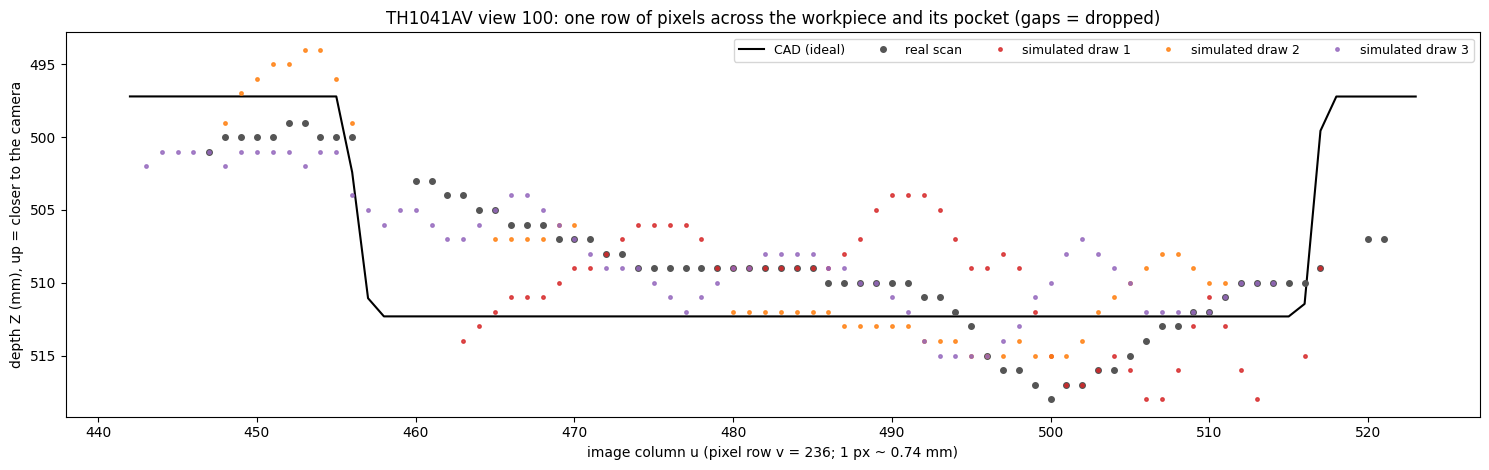

saved 6900 simulated points -> simulation/real2sim/test_11_real_pocket\TH1041AV\sim_view100_cad_frame.pcd


In [6]:
# ==========================================
# 4. CUT THROUGH THE POCKET + SAVE ONE SIMULATED CLOUD
# ==========================================
v = CUT_VIEW
rows = view_rows(test, TEST_WP, v)
T_cam = rs.real_camera_pose(raw_test, v, T_test)
maps = simulator.predict_maps(T_cam)
z_cad = maps["z"]
z_real = to_map(rows, (rows.z + rows.e_z).to_numpy())
# the image row through the middle of the pocket: the row with the most pixels next to a rise (pocket floor)
row = int(np.nanargmax(np.nansum(np.where(maps["closer_mm"] > 5, 1.0, 0.0), axis=1)))
cols = np.where(maps["mask"][row])[0]
fig, ax = plt.subplots(figsize=(15, 4.8))
ax.plot(cols, z_cad[row, cols], "k-", lw=1.5, label="CAD (ideal)")
ax.plot(cols, z_real[row, cols], "o", color="#555555", ms=4, label="real scan")
for i, color in enumerate(["#d62728", "#ff7f0e", "#9467bd"]):
    out = simulator.simulate(T_cam, np.random.default_rng([SEED, v, i]), maps=maps)
    ax.plot(cols, out["z_sim"][row, cols], ".", color=color, ms=5, alpha=0.8, label=f"simulated draw {i + 1}")
ax.invert_yaxis()
ax.set_xlabel(f"image column u (pixel row v = {row}; 1 px ~ {MM_PER_PX} mm)")
ax.set_ylabel("depth Z (mm), up = closer to the camera")
ax.set_title(f"{TEST_WP} view {v}: one row of pixels across the workpiece and its pocket (gaps = dropped)")
ax.legend(ncol=5, fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part5_cut_through_pocket.png"), dpi=110)
plt.show()

out = simulator.simulate(T_cam, np.random.default_rng([SEED, v]), maps=maps)
pcd = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(out["points_cad"]))
pcd_path = os.path.join(OUT_DIR, TEST_WP, f"sim_view{v}_cad_frame.pcd")
o3d.io.write_point_cloud(pcd_path, pcd)
print(f"saved {len(out['points_cad'])} simulated points -> {pcd_path}")

## Summary of Part 5 (model `model_10in_test-TH1041AV.pt`; recipes measured on validation views; checked on all 288 views of the unseen TH1041AV)
### Must understand
- **The simulator** turns any camera pose into a noisy scan:
  1. render the CAD;
  2. compute the 10 inputs;
  3. the model gives `p, μ, σ` per pixel;
  4. two blurred random fields roll the dice: Cloud A decides the dropouts, Cloud B the depth errors;
  5. the depth is rounded to whole mm, like the sensor;
  6. the kept pixels become 3D points.
- **The dice must be blurred, and the patch size was measured.** The real "surprises" (what the model cannot predict) are shared by neighbouring pixels over several millimetres, so the errors come in patches about 1 cm across. Each cloud is made of patches plus a share of a finer grain. The recipe that reproduces the real curve was found by trying combinations (section 1 figure):

  | Cloud | Patches | Finer grain |
  |---|---|---|
  | B, depth | 5.5 px (~4.1 mm) | 18% of 1.25 px |
  | A, drops | 5.0 px (~3.7 mm) | none |

  `σ` was widened by ×1.05, because on the validation views only 65.9% of errors fell within ±1σ.
- **The simulated scans have the same statistics as the real ones**, on a workpiece used for neither training nor the recipes:

  | | Real | Simulated |
  |---|---|---|
  | dropout | 22.5% | 22.8% |
  | `e_z` median | +0.53 mm | +0.59 mm |
  | `e_z` 10–90% | −3.0 … +5.1 mm | −3.1 … +5.3 mm |
  | `e_z` std | 3.32 mm | 3.44 mm |

  - Dropout vs distance to an edge: the real and simulated curves lie on top of each other.
  - The step pattern: next to a drop-off the depth reads too far; next to a rise it reads too close, in both.
  - Per view: views that drop more in reality also drop more in simulation (correlation 0.77, average difference 2.8 percentage points). The rest is the randomness of the patches.
- **The surface is as smooth as the real one** (section 3b). The difference in depth between neighbouring pixels on flat areas is 0.64 mm simulated vs 0.66 mm real.
  - The first recipe (each pixel with 14% of its own shake, no rounding) gave 1.05 mm, so it was too grainy. It was replaced.
  - Right at an edge the simulation is now slightly smoother than the real scan (1.80 vs 2.06 mm).
- **One simulated scan is not a copy of the real one.** The patches are random, so each draw (and the real scan) has them in different places. Section 2 shows the same *kind* of scan; section 4 shows three draws next to the real one.
- **Known differences:**
  1. **No table, so no points off the CAD outline.** The real sensor makes the table right next to the walls read too high, a low "ramp" at the foot of the block: about 8% of the real points near the part in a side check. The model only learned CAD pixels, so the simulator cannot produce the table or this ramp.
  2. **Point spacing.** The simulator gives one point per 960×540 pixel (~0.74 mm apart). The real saved scans are 0.5 mm voxel clouds. This matters when comparing point clouds (Part 6).

### Know what it does
- `real2sim_sim.py`:
  - `NoiseRecipe` (patches + finer grain), `noise_field`: one blurred cloud;
  - `field_correlation`: the curves in section 1;
  - `Simulator.predict_maps`, `Simulator.simulate` (with `round_mm`).
- `rs.input_maps`: the 10 inputs for any pose, from the CAD only.
- Every simulated view uses its own fixed seed (`[42, view]`), so a rerun gives the same scan.
- Saved:
  - `simulation/real2sim/test_11_real_pocket/simulator_test-TH1041AV.json`: the recipes, `σ` scale and model, so Part 6 rebuilds the same simulator with `Simulator.from_config`.
  - `simulation/real2sim/test_11_real_pocket/TH1041AV/sim_view100_cad_frame.pcd`: one simulated scan to open in Open3D.

### Next (Part 6, export)
Write simulated scans in the format the 4_2 / 6 pipeline reads (`viewpoint_simulated_noise_*.pcd`). Open choices:
- which viewpoints;
- which frame (robot base, like the real `view{i}.pcd`);
- which point spacing;
- whether the pipeline removes the table.

A simple way to match the real 0.5 mm clouds is to simulate on the full 1920×1080 grid (the inputs do not depend on the grid size) and voxel-downsample at 0.5 mm, like `2_2`.